#Monty Hall Problem with Monte Carlo Simulations

The Monty Hall problem is a well-known probability puzzle inspired by the game show Let’s Make a Deal, hosted by Monty Hall.

In the game show, you’re presented with three doors. Behind one is a car; behind the other two, goats. You pick a door, hoping for the car. Monty, who knows what’s behind each door, opens one of the remaining two to reveal a goat. He then gives you a choice: stick with your original door or switch to the other unopened one.

What should you do? Stay or switch?

In [13]:
#import necessary libraries

import numpy as np
import random
from random import randrange
from matplotlib import pyplot as plt

##Working Through the Monty Hall Decision Making Process

#### **Step 1:** Get the player's input about their choice of door

- Store the selected door in a variable called `picked_door`.

- Remove the `picked_door` from the list of `doors`.


In [14]:
#Pick one door and remove it from the available doors

winning_door = randrange(3)
random.seed(23) # Set the random number generator
doors = [0,1,2]

def choice_one (picked_door):
    if picked_door == winning_door:
        print("You win")
    else:
         doors.remove(picked_door)
         print("You picked door", str(picked_door) + ".")
         print("The remaining doors are therefore:", doors)
    return picked_door

picked_door = choice_one(0)

You picked door 0.
The remaining doors are therefore: [1, 2]


The `reveal_empty_door()` function simulates the game show host’s action in the Monty Hall problem, he reveals a non-winning door.
- The host never opens the door hiding the prize = reflecting the host’s knowledge and intentional behaviour.

In [15]:
def reveal_empty_door(doors, winning_door):
    sample_from = [] #Host cannot open the door that is the winning door. So the host has 1 or 2 candidate doors.
    if len(doors) != 2:
        print("There is an issue!")
        return None
    else:
        if doors[0]!= winning_door:
            sample_from.append(doors[0])
        if doors[1]!= winning_door:
            sample_from.append(doors[1])
    return random.choice(sample_from)

reveal_empty_door([0,2], winning_door) # This is the host's choice, note that the door is 1

2

The host reveals an empty door, removes it from the available choices and identifies the remaining unopened door, which is the contestant's alternative if they choose to switch. This step is central to the decision-making process in the Monty Hall problem.

In [16]:
open_door = reveal_empty_door(doors, winning_door)
print("The host reveals door", open_door)
assert open_door in doors, (doors, open_door, winning_door)
# assert used to debug code, tests if a condition in the code is True, otherwise will raise AssertionError
# Here it tests if there is None inside doors
doors.remove(open_door)
remaining_door = doors[0]

The host reveals door 2


The contestant is reminded of their initial choice and given the option to switch to the other unopened door, highlighting the critical decision point in the Monty Hall problem.

In [17]:
print("You initially picked door", picked_door, "but you can switch to door", remaining_door)

You initially picked door 0 but you can switch to door 1


The contestant chooses whether to switch doors or stay with the original selection. If `yes_no` is 'yes', the choice is updated to the other unopened door. Otherwise, the original choice is retained. A message is printed indicating the contestant's final selection.

In [18]:
yes_no = 'yes'  # Change to 'no' if you want to keep the original door

if yes_no == "yes":
    print("You switched to door", remaining_door)
    picked_door = remaining_door
else:
    print("You keep your door", picked_door)

You switched to door 1


In [19]:
print("Let's see if we won: (True means you are the winner!)")
print(picked_door == winning_door)

Let's see if we won: (True means you are the winner!)
True


## Simulating a Monty Hall Game Round using a Function

The `simulate_round()` function runs a single Monty Hall game round. The contestant selects a door, the prize is randomly placed and the host reveals a non-winning door.
- The contestant chooses yes/ no to switch
- The function returns 1 for a win and 0 for a loss

In [20]:
def simulate_round(picked_door, yes_no):
    doors = [0,1,2]
    winning_door = randrange(3) # it can be 0, 1, or 2! We don't know the truth yet.
    assert picked_door in (0,1,2), picked_door
    doors.remove(picked_door)
    open_door = reveal_empty_door(doors, winning_door)
    doors.remove(open_door)
    remaining_door = doors[0]
    if yes_no == "yes":
        picked_door = remaining_door
    return int(picked_door == winning_door)


#Testing the function, picking door 2 and choosing not to switch
simulate_round(2, "no")

0

## Simulating multiple rounds of the Monty Hall Game

The Monty Hall game is simulated 30,000 times, with the contestant always choosing door 1 and never switching.

Each round's outcome is recorded, and the cumulative win ratio is calculated to show how the winning percentage evolves over time.



In [21]:
picked_door = 1 #fix a door (0,1, or 2)
yes_no = "no" #let's start with the strategy of keeping our door!
simulate = 30000 #number of times to simulate
results = np.zeros(simulate) #a lot of zeros
for i in range(simulate):
    results[i] = simulate_round(picked_door, yes_no)
ratios = np.cumsum(results) / (np.arange(1,simulate+ 1))
print(ratios)

[1.         0.5        0.33333333 ... 0.32708847 0.3271109  0.32713333]


The plot below shows first 3,000 rounds.
- x-axis = number of rounds played
- y-axis = cumulative win percentage.
- dashed horizontal line = theoretical probability of winning (0.3333) by staying with the initial choice

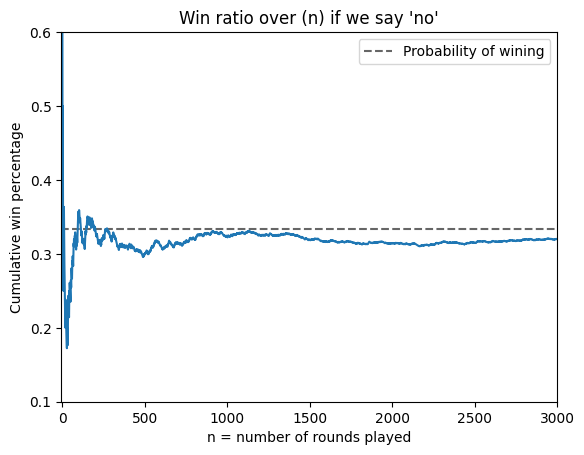

In [22]:
plot_limit = 3000 #plot how the ratio changes oby increasing $n$
x = np.arange(1, plot_limit + 1)
y = ratios[:plot_limit]
plt.title(r"Win ratio over (n) if we say 'no'")
plt.xlabel("n = number of rounds played")
plt.ylabel(r"Cumulative win percentage")
plt.axhline(y = 1/3, color = 'k', linestyle='--', alpha = 0.6, label = r"Probability of wining")
assert plot_limit <= len(ratios), (plot_limit, len(ratios))
plt.plot(x,y)
plt.xlim(-5,plot_limit)
plt.ylim(0.1,0.6)
plt.legend()
plt.show()

The plot shows that the win ratio converges towards the expected value, 0.3333.

## New Simulation with Switching Strategy
- `picked_door` = 2
- user chooses to switch (`yes_no` = 'yes')
- simulation is run for 10,000 iterations.

In [24]:
picked_door = 2
yes_no = 'yes'
simulate = 10000

results_Q2 = np.zeros(simulate)
for i in range(simulate):
    results_Q2[i] = simulate_round(picked_door, yes_no)
ratios = np.cumsum(results_Q2)/ (np.arange(1, simulate+1))

print(results_Q2)
print(ratios)

[1. 1. 1. ... 0. 1. 1.]
[1.         1.         1.         ... 0.66863373 0.66866687 0.6687    ]


The simulations for Question 2 are plotted below.

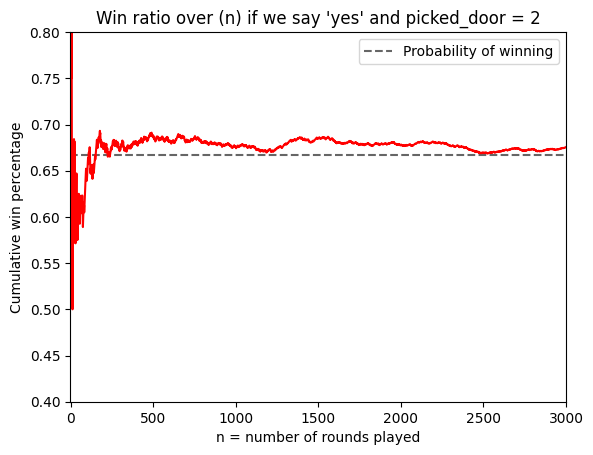

In [25]:
plot_limit = 3000
x = np.arange(1, plot_limit + 1)
y = ratios[:plot_limit]
plt.title(r"Win ratio over (n) if we say 'yes' and picked_door = 2")
plt.xlabel("n = number of rounds played")
plt.ylabel(r"Cumulative win percentage")
plt.axhline(y = 2/3, color = 'k', linestyle='--', alpha = 0.6, label = r"Probability of winning")
plt.plot(x,y, color='r')
plt.xlim(-5,plot_limit)
plt.ylim(0.4,0.8)
plt.legend()
plt.show()

##Modification of Game with Coin Flip

Each time the host offers you the option to switch doors, you flip a biased coin with probability $\theta$ of landing on 'H'. If it lands on 'H', you switch; otherwise, you stick with your original choice.

In [26]:
def simulate_with_coins(picked_door, theta):
    doors = [0,1,2]
    winning_door = randrange(3) # it can be 0, 1, or 2! We don't know the truth yet.
    doors.remove(picked_door)
    open_door = reveal_empty_door(doors, winning_door)
    doors.remove(open_door)
    remaining_door = doors[0]
    flip = np.random.uniform(0,1)

    if flip <= theta:
        picked_door = remaining_door
    else:
        picked_door = picked_door
    return int(picked_door == winning_door)

simulate_with_coins(0, 0.2)

1

## Simulating the Modified Monty Hall Problem
- `picked_door` = 1
- $\theta = 0.6$
- `simulate` = 30,000

In [27]:
picked_door = 1
theta = 0.6
simulate = 30000

results_Q3 = np.zeros(simulate)
for i in range(simulate):
    results[i]=simulate_with_coins(picked_door, theta)

ratios = np.cumsum(results) / (np.arange(1,simulate+ 1))
print(f"We win about {ratios[-1]*100:.2f}% of the time!")

We win about 53.55% of the time!


##Modified Monty Hall Problem with Payout

Imagine this:

- You’re playing a modified version of the Monty Hall game.

- You start with £5. Each round costs £1 to play.

- If you pick the winning door, you earn £2 (recovering your £1 and gaining a £1 profit). If you lose, you forfeit the £1.

- Your strategy: switch doors based on a coin flip. If a random number between 0 and 1 is less than or equal to $\theta$, you switch; otherwise, you stick with your original choice.

In [29]:
def reveal_empty_door(doors, winning_door):
    options = []
    for k in doors:
        if k != winning_door:
            options.append(k)
    return random.choice(options)
# reveal open door function
# options is the remaining options, the doors the host can open
# for k in doors > iterates through the two remaining doors
# if k != winning door > checks that k is not winning door as the host can't open winning door
# options.append(k) > if k isn't winning door it is an empty door, so able to be opened
# host opens door in options list

def simulate_round(picked_door, theta):
    """
    Inputs: picked_door (0 1 or 2), decision of switching the door ("yes" or "no")
    Returns: whether or not we win the prize (1: win, 0: lose)
    """
    doors = [0,1,2]
    winning_door = random.randrange(3) # it can be 0, 1, or 2! We don't know the truth yet.
    doors.remove(picked_door)
    open_door = reveal_empty_door(doors, winning_door)
    doors.remove(open_door)
    remaining_door = doors[0]
    flip = np.random.uniform(0,1)
    if flip <= theta:
        picked_door = remaining_door

    return int(picked_door == winning_door)

def simulate_with_coins(picked_door, theta):
    """
    Inputs: picked_door (0 1 or 2), decision of switching the door ("yes" or "no")
    Returns: whether or not we win the prize (1: win, 0: lose)
    """
    doors = [0,1,2]
    winning_door = random.randrange(3) # it can be 0, 1, or 2! We don't know the truth yet.
    doors.remove(picked_door)
    open_door = reveal_empty_door(doors, winning_door)
    doors.remove(open_door)
    remaining_door = doors[0]
    flip = np.random.uniform(0,1)

    if flip <= theta:
        picked_door = remaining_door

    return int(picked_door == winning_door)

def survival_probability(theta, num_rounds, num_simulations):
    """
    Simulates the Monty Hall game and estimates the probability of survival.

    Args:
        theta (float): Probability threshold for switching doors.
        num_rounds (int): Number of rounds to simulate.
        num_simulations (int): Number of simulation runs.

    Returns:
        float: Estimated probability of survival.
    """
    random.seed(42)
    np.random.seed(42)
    survival_count = 0
    for _ in range(num_simulations):
        money = 5
        for _ in range(num_rounds):
            money -= 1  # Pay to play ## a-=b > means a = a - b
            if money <= 0:
                break
            picked_door = random.randint(0, 2)
            if simulate_with_coins(picked_door, theta):
                money += 2  # Win £2 (profit of £1)
        if money > 0:
            survival_count += 1

    survival_probability =  survival_count / num_simulations

    return survival_probability

picked_door = 2

survival_probability(0.8, 6, 2)

1.0

## Simulating Modified Monty Hall with Payout Structure
- `theta` = 0.4
- `num_rounds` = 10
- `num_simulations` = 10000

In [31]:
theta = 0.4
num_rounds = 10
num_simulations = 10000
survival = survival_probability(theta, num_rounds, num_simulations)

print(f"Estimated survival probability: {survival}")

Estimated survival probability: 0.774
